In [1]:
!pip install -q pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 142.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 110.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 113.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 153.7 MB/s eta 0:00:00


In [2]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import pennylane as qml
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda")      # the 4-qubit simulation and small backbone are fast on CPU
print("PennyLane:", qml.__version__)

PennyLane: 0.45.1


In [3]:
N_QUBITS  = 16
N_REPS    = 1                    # BasicEntanglerLayers repetitions
N_CLASSES = 3
CLASS_NAMES = ["inactive", "intermediate", "active"]

PRETRAINED      = False           # load backbone weights from your trained 3-class DNN checkpoint
FREEZE_BACKBONE = False           # True: train only the quantum head (transfer learning)
DNN3_CKPT_PATH  = ""

LR_HEAD     = 1e-2               # pre_net + quantum weights + post_net
LR_BACKBONE = 1e-4               # only used if FREEZE_BACKBONE = False
EPOCHS, PATIENCE = 100, 15

In [4]:
df = pd.read_csv("/content/hiv1_protease_padel_full.csv")

fp_cols = [c for c in df.columns if c.startswith("PubchemFP") or
           (c.startswith("FP") and c[2:].isdigit())]

X  = df[fp_cols].values.astype(np.float32)
y3 = df["three_class_label"].values.astype(int)      # 0 inactive, 1 intermediate, 2 active
print("Samples:", X.shape[0], "| features:", X.shape[1])
print("Class counts:", {CLASS_NAMES[i]: int((y3 == i).sum()) for i in range(N_CLASSES)})

X_tmp, X_te, y_tmp, y_te = train_test_split(X, y3, test_size=0.15, stratify=y3, random_state=SEED)
X_tr, X_va, y_tr, y_va   = train_test_split(X_tmp, y_tmp, test_size=0.1765,
                                            stratify=y_tmp, random_state=SEED)

vt = VarianceThreshold(0.01).fit(X_tr)
X_tr, X_va, X_te = vt.transform(X_tr), vt.transform(X_va), vt.transform(X_te)
kept_cols = [str(c) for c in np.array(fp_cols)[vt.get_support()]]
print("Features after variance filter:", X_tr.shape[1])
print("Train/Val/Test:", len(y_tr), len(y_va), len(y_te))

def make_loader(Xa, ya, shuffle, bs=64):
    ds = TensorDataset(torch.tensor(Xa, dtype=torch.float32),
                       torch.tensor(ya, dtype=torch.long))        # class indices must be long
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=shuffle)

train_loader      = make_loader(X_tr, y_tr, True)
train_eval_loader = make_loader(X_tr, y_tr, False)    # unshuffled copy for evaluation
val_loader        = make_loader(X_va, y_va, False)
test_loader       = make_loader(X_te, y_te, False)

Samples: 2577 | features: 881
Class counts: {'inactive': 213, 'intermediate': 348, 'active': 2016}
Features after variance filter: 394
Train/Val/Test: 1803 387 387


In [5]:
dev = qml.device("lightning.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # inputs : (batch, N_QUBITS) angles; weights : (N_REPS, N_QUBITS) trainable
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="X")
    qml.BasicEntanglerLayers(weights, wires=range(N_QUBITS))      # RX rotations + ring of CNOTs
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {"weights": (N_REPS, N_QUBITS)}

print(qml.draw(quantum_circuit)(torch.zeros(N_QUBITS), torch.zeros(N_REPS, N_QUBITS)))

 0: ─╭AngleEmbedding(M0)─╭BasicEntanglerLayers(M1)─┤  <Z>
 1: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 2: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 3: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 4: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 5: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 6: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 7: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 8: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
 9: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
10: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
11: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
12: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
13: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
14: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
15: ─╰AngleEmbedding(M0)─╰BasicEntanglerLayers(M1)─┤  <Z>

M0 = 
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0

In [6]:
class HybridMC(nn.Module):
    def __init__(self, in_dim, n_qubits=N_QUBITS, n_classes=N_CLASSES, freeze_backbone=False):
        super().__init__()
        self.freeze_backbone = freeze_backbone

        # ================= Classical backbone (same as the DNN) =================
        # ---- Block 1: in_dim -> 512 ----
        self.fc1   = nn.Linear(in_dim, 512)
        self.bn1   = nn.BatchNorm1d(512)
        self.act1  = nn.ReLU()
        self.drop1 = nn.Dropout(0.3)

        # ---- Block 2: 512 -> 256 ----
        self.fc2   = nn.Linear(512, 256)
        self.bn2   = nn.BatchNorm1d(256)
        self.act2  = nn.ReLU()
        self.drop2 = nn.Dropout(0.3)

        # ---- Block 3: 256 -> 64 ----
        self.fc3   = nn.Linear(256, 64)
        self.bn3   = nn.BatchNorm1d(64)
        self.act3  = nn.ReLU()
        self.drop3 = nn.Dropout(0.3)

        # ================= Quantum head (replaces the DNN's final Linear(64, 3)) =================
        self.pre_net  = nn.Linear(64, n_qubits)                         # 64 -> 4 features for the circuit
        self.qlayer   = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_net = nn.Linear(n_qubits, n_classes)                  # 4 expectation values -> 3 logits

        if freeze_backbone:
            for m in self.backbone_modules():
                for p in m.parameters():
                    p.requires_grad = False

    def backbone_modules(self):
        return [self.fc1, self.bn1, self.fc2, self.bn2, self.fc3, self.bn3]

    def head_modules(self):
        return [self.pre_net, self.qlayer, self.post_net]

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:                 # frozen backbone: no dropout, BN stats stay fixed
            for m in [self.drop1, self.drop2, self.drop3] + self.backbone_modules():
                m.eval()
        return self

    def forward(self, x):
        # Classical backbone
        x = self.drop1(self.act1(self.bn1(self.fc1(x))))
        x = self.drop2(self.act2(self.bn2(self.fc2(x))))
        x = self.drop3(self.act3(self.bn3(self.fc3(x))))

        # Quantum head
        q_in  = torch.tanh(self.pre_net(x)) * (np.pi / 2.0)    # angles in [-pi/2, pi/2]
        q_out = self.qlayer(q_in).float()                      # (batch, N_QUBITS), values in [-1, 1]
        return self.post_net(q_out)                            # raw logits (batch, 3)

In [7]:
model_h = HybridMC(X_tr.shape[1], freeze_backbone=FREEZE_BACKBONE)

if PRETRAINED:
    dnn_ckpt = torch.load(DNN3_CKPT_PATH, map_location="cpu", weights_only=False)
    assert dnn_ckpt["in_dim"] == X_tr.shape[1], "Feature count differs from the DNN3 checkpoint"
    assert [str(c) for c in dnn_ckpt["kept_cols"]] == kept_cols, "Feature columns differ from the DNN3 checkpoint"
    missing, unexpected = model_h.load_state_dict(dnn_ckpt["state_dict"], strict=False)
    print("Not loaded (new quantum head, expected):", sorted({k.split('.')[0] for k in missing}))
    print("Ignored from DNN3 (old output layer, expected):", unexpected)

model_h = model_h.to(device)

n_total     = sum(p.numel() for p in model_h.parameters())
n_trainable = sum(p.numel() for p in model_h.parameters() if p.requires_grad)
print(f"Parameters: total {n_total:,} | trainable {n_trainable:,} | quantum circuit weights {N_REPS * N_QUBITS}")

Parameters: total 352,787 | trainable 352,787 | quantum circuit weights 16


In [8]:
counts  = np.bincount(y_tr, minlength=N_CLASSES)
class_w = torch.tensor(len(y_tr) / (N_CLASSES * counts), dtype=torch.float32).to(device)
print("Class weights:", dict(zip(CLASS_NAMES, class_w.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=class_w)

head_params  = [p for m in model_h.head_modules() for p in m.parameters()]
param_groups = [{"params": head_params, "lr": LR_HEAD}]
if not FREEZE_BACKBONE:
    param_groups.append({"params": [p for m in model_h.backbone_modules() for p in m.parameters()],
                         "lr": LR_BACKBONE})

optimizer = torch.optim.AdamW(param_groups, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)

@torch.no_grad()
def predict_proba_mc(model, loader):
    model.eval()
    out = [torch.softmax(model(xb.to(device)), dim=1).cpu() for xb, _ in loader]
    p = torch.cat(out).numpy().astype(np.float64)
    return p / p.sum(1, keepdims=True)                 # exact row sums for sklearn's AUC check

@torch.no_grad()
def eval_loss_mc(model, loader):
    model.eval(); total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        total += criterion(model(xb), yb).item() * len(yb); n += len(yb)
    return total / n

Class weights: {'inactive': np.float32(4.03), 'intermediate': np.float32(2.46), 'active': np.float32(0.43)}


In [9]:
BEST_WEIGHTS_PATH = "hiv1_pennylane_hybrid3_best_weights.pt"
CHECKPOINT_PATH   = "hiv1_pennylane_hybrid3_best_checkpoint.pt"

best_f1, best_state, best_epoch, wait = -1.0, None, 0, 0
history_h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    # ---- train ----
    model_h.train(); running, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model_h(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb); n += len(yb)

    # ---- evaluate ----
    train_pred = predict_proba_mc(model_h, train_eval_loader).argmax(1)
    val_pred   = predict_proba_mc(model_h, val_loader).argmax(1)
    train_acc  = accuracy_score(y_tr, train_pred)
    val_acc    = accuracy_score(y_va, val_pred)
    val_f1     = f1_score(y_va, val_pred, average="macro")

    history_h["train_loss"].append(running / n)
    history_h["val_loss"].append(eval_loss_mc(model_h, val_loader))
    history_h["train_acc"].append(train_acc)
    history_h["val_acc"].append(val_acc)
    history_h["val_f1"].append(val_f1)
    scheduler.step(val_f1)

    # ---- early stopping / keep and save best model (by validation macro-F1) ----
    if val_f1 > best_f1:
        best_f1, best_epoch, wait = val_f1, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model_h.state_dict().items()}
        torch.save(best_state, BEST_WEIGHTS_PATH)
    else:
        wait += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | loss {history_h['train_loss'][-1]:.4f}/{history_h['val_loss'][-1]:.4f} "
              f"| acc {train_acc:.4f}/{val_acc:.4f} | val macro-F1 {val_f1:.4f} "
              f"| {(time.time() - t_start) / 60:.1f} min")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best val macro-F1 {best_f1:.4f} at epoch {best_epoch})")
        break

model_h.load_state_dict(best_state)

# Full checkpoint (plain Python types only, so it loads in PyTorch's safe mode)
torch.save({
    "state_dict": best_state,
    "in_dim": int(X_tr.shape[1]),
    "kept_cols": kept_cols,
    "n_qubits": N_QUBITS,
    "n_reps": N_REPS,
    "n_classes": N_CLASSES,
    "class_names": CLASS_NAMES,
    "freeze_backbone": bool(FREEZE_BACKBONE),
    "best_val_f1": float(best_f1),
    "best_epoch": int(best_epoch),
}, CHECKPOINT_PATH)

print(f"\nBest model: epoch {best_epoch}, val macro-F1 {best_f1:.4f}")
print(f"Saved: {BEST_WEIGHTS_PATH} and {CHECKPOINT_PATH}")

epoch   1 | loss 1.1010/1.0908 | acc 0.7654/0.7519 | val macro-F1 0.3762 | 5.1 min
epoch   5 | loss 0.9806/0.9241 | acc 0.7155/0.6951 | val macro-F1 0.5162 | 25.5 min
epoch  10 | loss 0.8074/0.8580 | acc 0.7582/0.7339 | val macro-F1 0.5694 | 50.9 min
epoch  15 | loss 0.6817/0.8758 | acc 0.7820/0.7468 | val macro-F1 0.5953 | 76.3 min
epoch  20 | loss 0.6538/0.8466 | acc 0.7931/0.7287 | val macro-F1 0.5748 | 101.8 min
epoch  25 | loss 0.6006/0.8584 | acc 0.8486/0.7726 | val macro-F1 0.6138 | 127.2 min
epoch  30 | loss 0.5758/0.8832 | acc 0.8308/0.7494 | val macro-F1 0.5858 | 152.6 min
epoch  35 | loss 0.5519/0.8735 | acc 0.8453/0.7649 | val macro-F1 0.6054 | 178.1 min
epoch  40 | loss 0.5351/0.8991 | acc 0.8514/0.7623 | val macro-F1 0.5988 | 203.5 min
Early stopping at epoch 40 (best val macro-F1 0.6138 at epoch 25)

Best model: epoch 25, val macro-F1 0.6138
Saved: hiv1_pennylane_hybrid3_best_weights.pt and hiv1_pennylane_hybrid3_best_checkpoint.pt


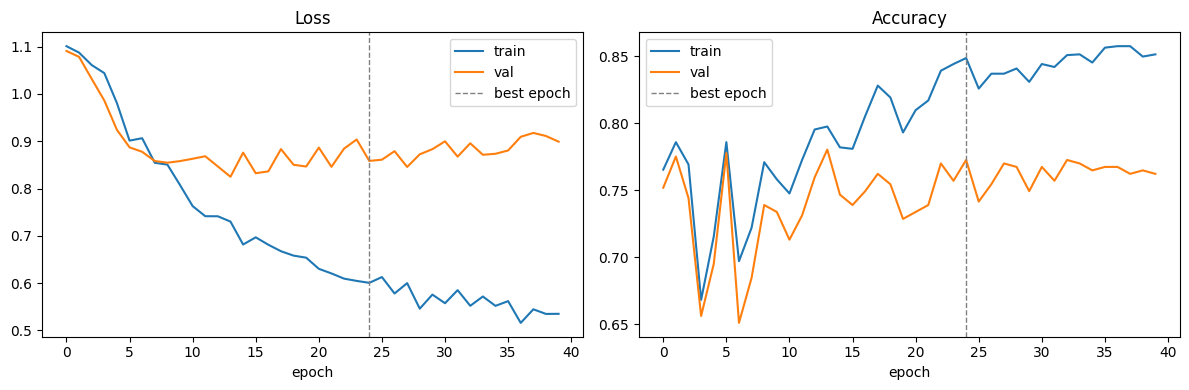

Best epoch: 25
Train acc: 0.8486 | Val acc: 0.7726 | Val macro-F1: 0.6138


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history_h["train_loss"], label="train")
ax[0].plot(history_h["val_loss"], label="val")
ax[0].axvline(best_epoch - 1, color="gray", ls="--", lw=1, label="best epoch")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history_h["train_acc"], label="train")
ax[1].plot(history_h["val_acc"], label="val")
ax[1].axvline(best_epoch - 1, color="gray", ls="--", lw=1, label="best epoch")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()

plt.tight_layout(); plt.show()

i = best_epoch - 1
print(f"Best epoch: {best_epoch}")
print(f"Train acc: {history_h['train_acc'][i]:.4f} | Val acc: {history_h['val_acc'][i]:.4f} "
      f"| Val macro-F1: {history_h['val_f1'][i]:.4f}")

pd.DataFrame(history_h).round(4).to_csv("pennylane_hybrid3_training_history.csv", index_label="epoch")

In [11]:
test_prob_h = predict_proba_mc(model_h, test_loader)       # (n_test, 3)
test_pred_h = test_prob_h.argmax(1)

print(f"Test samples:           {len(y_te)}")
print(f"Test accuracy:          {accuracy_score(y_te, test_pred_h):.4f}   (chance ~ 0.33)")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_te, test_pred_h):.4f}")
print(f"Test macro F1:          {f1_score(y_te, test_pred_h, average='macro'):.4f}")
print(f"Test weighted F1:       {f1_score(y_te, test_pred_h, average='weighted'):.4f}")
print(f"Test ROC-AUC (OvR):     {roc_auc_score(y_te, test_prob_h, multi_class='ovr', average='macro'):.4f}")

print("\nPer-class report:")
print(classification_report(y_te, test_pred_h, target_names=CLASS_NAMES, digits=3, zero_division=0))

res_h = pd.DataFrame({"PennyLane hybrid 3-class": {
    "accuracy":     accuracy_score(y_te, test_pred_h),
    "balanced_acc": balanced_accuracy_score(y_te, test_pred_h),
    "macro_F1":     f1_score(y_te, test_pred_h, average="macro"),
    "ROC_AUC_ovr":  roc_auc_score(y_te, test_prob_h, multi_class="ovr", average="macro"),
}}).T.round(3)
display(res_h)
res_h.to_csv("pennylane_hybrid3_test_results.csv")

Test samples:           387
Test accuracy:          0.7700   (chance ~ 0.33)
Test balanced accuracy: 0.6468
Test macro F1:          0.6074
Test weighted F1:       0.7907
Test ROC-AUC (OvR):     0.8538

Per-class report:
              precision    recall  f1-score   support

    inactive      0.471     0.500     0.485        32
intermediate      0.364     0.615     0.457        52
      active      0.943     0.825     0.880       303

    accuracy                          0.770       387
   macro avg      0.593     0.647     0.607       387
weighted avg      0.826     0.770     0.791       387



,accuracy,balanced_acc,macro_F1,ROC_AUC_ovr
PennyLane hybrid 3-class,0.77,0.647,0.607,0.854


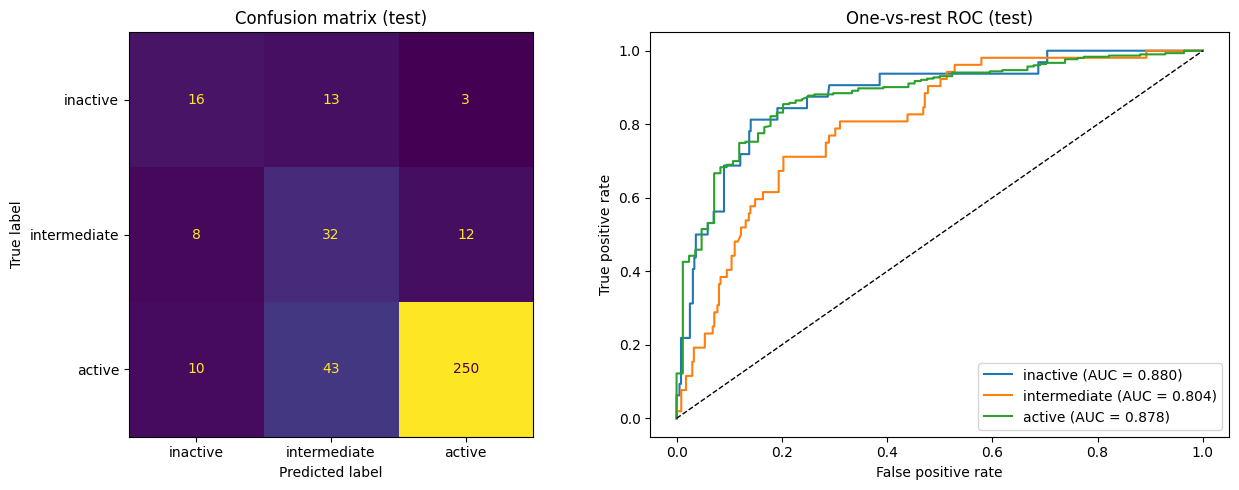

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_te, test_pred_h, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")

Y_bin = label_binarize(y_te, classes=[0, 1, 2])
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(Y_bin[:, i], test_prob_h[:, i])
    ax[1].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(Y_bin[:, i], test_prob_h[:, i]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("One-vs-rest ROC (test)"); ax[1].legend()

plt.tight_layout(); plt.show()

In [13]:
idx = np.arange(len(y3))
idx_tmp, idx_te = train_test_split(idx, test_size=0.15, stratify=y3, random_state=SEED)
assert np.array_equal(y3[idx_te], y_te), "Index split does not match the split cell"

pred_df_h = pd.DataFrame({
    "molecule_chembl_id": df.iloc[idx_te]["molecule_chembl_id"].values,
    "canonical_smiles":   df.iloc[idx_te]["canonical_smiles"].values,
    "pIC50":              df.iloc[idx_te]["pIC50"].values,
    "true_label":         y_te,
    "true_class":         [CLASS_NAMES[i] for i in y_te],
    "pred_label":         test_pred_h,
    "pred_class":         [CLASS_NAMES[i] for i in test_pred_h],
    "prob_inactive":      test_prob_h[:, 0].round(4),
    "prob_intermediate":  test_prob_h[:, 1].round(4),
    "prob_active":        test_prob_h[:, 2].round(4),
})
pred_df_h["correct"] = pred_df_h.true_label == pred_df_h.pred_label
pred_df_h.to_csv("pennylane_hybrid3_test_predictions.csv", index=False)
display(pred_df_h.groupby("true_class").correct.mean().rename("accuracy per class"))

# from google.colab import files
# files.download(CHECKPOINT_PATH)
# files.download("pennylane_hybrid3_test_results.csv")
# files.download("pennylane_hybrid3_test_predictions.csv")

,accuracy per class
true_class,
active,0.825083
inactive,0.500000
intermediate,0.615385


In [14]:
ckpt_h = torch.load("/content/hiv1_pennylane_hybrid3_best_checkpoint.pt", map_location="cpu")
model_r = HybridMC(ckpt_h["in_dim"], ckpt_h["n_qubits"], ckpt_h["n_classes"], ckpt_h["freeze_backbone"]).to(device)
model_r.load_state_dict(ckpt_h["state_dict"])
model_r.eval()
print("Loaded | best epoch:", ckpt_h["best_epoch"], "| val macro-F1:", round(ckpt_h["best_val_f1"], 4))

prob_r = predict_proba_mc(model_r, test_loader)
pred_r = prob_r.argmax(1)

print(f"\nTest accuracy:          {accuracy_score(y_te, pred_r):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_te, pred_r):.4f}")
print(f"Test macro F1:          {f1_score(y_te, pred_r, average='macro'):.4f}")
print(f"Test ROC-AUC (OvR):     {roc_auc_score(y_te, prob_r, multi_class='ovr', average='macro'):.4f}")
print("\nConfusion matrix (rows = true, cols = predicted; order: inactive, intermediate, active):")
print(confusion_matrix(y_te, pred_r))

# Sanity check: should be ~0 if the reload matches the trained model
print("\nMax difference vs earlier test_prob_h:", np.abs(prob_r - test_prob_h).max())

Loaded | best epoch: 25 | val macro-F1: 0.6138

Test accuracy:          0.7700
Test balanced accuracy: 0.6468
Test macro F1:          0.6074
Test ROC-AUC (OvR):     0.8538

Confusion matrix (rows = true, cols = predicted; order: inactive, intermediate, active):
[[ 16  13   3]
 [  8  32  12]
 [ 10  43 250]]

Max difference vs earlier test_prob_h: 0.0


In [15]:
from google.colab import files
files.download(CHECKPOINT_PATH)
# files.download("pennylane_hybrid3_test_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Getting the test set back

In [16]:
# X_list, y_list = [], []
# for xb, yb in test_loader:
#     X_list.append(xb.numpy()); y_list.append(yb.numpy())
# X_test = np.vstack(X_list)
# y_test = np.concatenate(y_list)
# assert np.array_equal(y_test, y_te), "test_loader labels do not match y_te"

# # Fingerprint bits are 0/1, so store them as small integers
# if np.isin(X_test, [0, 1]).all():
#     X_test = X_test.astype(np.int8)

# CLASS_NAMES = ["inactive", "intermediate", "active"]

# out = pd.DataFrame({
#     "true_label":        y_test,
#     "true_class":        [CLASS_NAMES[i] for i in y_test],
#     "pred_label":        pred_r,
#     "pred_class":        [CLASS_NAMES[i] for i in pred_r],
#     "prob_inactive":     prob_r[:, 0].round(4),
#     "prob_intermediate": prob_r[:, 1].round(4),
#     "prob_active":       prob_r[:, 2].round(4),
# })
# out["correct"] = out.true_label == out.pred_label

# # Append the feature columns (the exact inputs the model saw)
# out = pd.concat([out, pd.DataFrame(X_test, columns=ckpt_h["kept_cols"])], axis=1)

# out.to_csv("pennylane_hybrid3_test_set_with_results.csv", index=False)
# print("Saved:", out.shape, "| accuracy:", round(out.correct.mean(), 4))

In [17]:
# from google.colab import files
# files.download("pennylane_hybrid3_test_set_with_results.csv")